# M1-B1 — Modélisation

Tâches 4 à 8 : premier modèle, v1 rejouée, pipeline v2, validation et réglage, verdict.

Le chargement et le découpage viennent de `train.py`. Seule la tâche 8 lit le jeu de test.

In [1]:
import os
import sys
import tempfile
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, fbeta_score, precision_score, recall_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_validate, train_test_split
from sqlalchemy import create_engine, text

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

# Avertissement sans effet (scikit-learn 1.6.1 avec un SciPy plus récent)
os.environ["PYTHONWARNINGS"] = "ignore:Unknown solver options"
warnings.filterwarnings("ignore", message="Unknown solver options")

from features import LEAKY_COLUMNS, NEW_CATEGORICAL, NEW_NUMERICAL, RAW_FEATURES, TARGET, USELESS_COLUMNS, add_features
from model.train_baseline import FEATURES as V1_FEATURES
from model.train_baseline import build_pipeline as build_v1
from train import CV, F2, HYPERPARAMETERS, build_pipeline, evaluate, load_data, split_train_test

engine = create_engine(os.environ["DATABASE_URL"])
df = load_data(engine)
train, test = split_train_test(df)
y_train = train[TARGET]

print(f"Entraînement : {len(train)} réservations, arrivées du {train['arrival_date'].min().date()} au {train['arrival_date'].max().date()}")
print(f"Taux d'annulation sur l'entraînement : {y_train.mean():.1%}")
print(f"Test : {len(test)} réservations, mises de côté jusqu'à la tâche 8")

Entraînement : 58792 réservations, arrivées du 2015-07-01 au 2016-08-31
Taux d'annulation sur l'entraînement : 35.6%
Test : 19911 réservations, mises de côté jusqu'à la tâche 8


## Tâche 4 — Premier modèle

Forêt aléatoire sur toutes les colonnes, encodées avec `pd.get_dummies`, dates exclues. Le score est mesuré sur 25 % du jeu d'entraînement.

In [2]:
def modele_naif(colonnes_retirees=()):
    """Forêt aléatoire : score de validation et 10 variables les plus importantes."""
    X = pd.get_dummies(train.drop(columns=[TARGET, "arrival_date", "reservation_status_date", *colonnes_retirees]))
    X_a, X_val, y_a, y_val = train_test_split(X, y_train, test_size=0.25, stratify=y_train, random_state=42)
    foret = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42).fit(X_a, y_a)
    print(f"{X.shape[1]} colonnes | accuracy de validation : {foret.score(X_val, y_val):.4f}")
    importances = pd.Series(foret.feature_importances_, index=X.columns).sort_values(ascending=False)
    return importances.head(10).round(3).to_frame("importance")


modele_naif()

233 colonnes | accuracy de validation : 1.0000


,importance
reservation_status_Canceled,0.328
reservation_status_Check-Out,0.315
deposit_type_Non Refund,0.079
previous_cancellations,0.040
deposit_type_No Deposit,0.039
country_PRT,0.025
lead_time,0.018
total_of_special_requests,0.014
reservation_status_No-Show,0.013
agent,0.011


L'accuracy est de 100 %. `reservation_status_Canceled` et `reservation_status_Check-Out` portent 64 % de l'importance.

### Contenu de `reservation_status`

Requête limitée à la période d'entraînement.

In [3]:
query = text("""
    SELECT reservation_status,
           is_canceled,
           COUNT(*)                                                AS nb_reservations,
           ROUND(AVG(reservation_status_date - arrival_date), 1)   AS jours_entre_arrivee_et_statut
    FROM reservations
    WHERE arrival_date <= :date_limite
    GROUP BY reservation_status, is_canceled
    ORDER BY reservation_status
""")
pd.read_sql(query, engine, params={"date_limite": train["arrival_date"].max().date()})

,reservation_status,is_canceled,nb_reservations,jours_entre_arrivee_et_statut
0,Canceled,1,20206,-75.4
1,Check-Out,0,37883,3.4
2,No-Show,1,703,-0.2


`reservation_status` reprend la cible : `Canceled` et `No-Show` correspondent à `is_canceled = 1`, `Check-Out` à 0. Ce statut est connu après le dénouement de la réservation.

`reservation_status_date` dépend aussi du dénouement : 75 jours avant l'arrivée en moyenne pour une annulation, 3 jours après pour un séjour honoré.

### Sans `reservation_status`

In [4]:
modele_naif(["reservation_status"])

230 colonnes | accuracy de validation : 0.9167


,importance
lead_time,0.082
country_PRT,0.077
deposit_type_Non Refund,0.076
reservation_id,0.069
deposit_type_No Deposit,0.063
previous_cancellations,0.058
adr,0.053
total_of_special_requests,0.049
agent,0.041
arrival_date_day_of_month,0.035


L'accuracy passe à 91,7 %. `reservation_id` est la 4e variable la plus importante. Les autres colonnes sont vérifiées ci-dessous.

In [5]:
# Lien entre reservation_id et l'ordre des arrivées
print("Corrélation de rang entre reservation_id et arrival_date :",
      round(train["reservation_id"].corr(train["arrival_date"].astype("int64"), method="spearman"), 4))

# Taux d'annulation selon cinq indices
indices = {
    "chambre attribuée différente de la chambre réservée": train["assigned_room_type"] != train["reserved_room_type"],
    "au moins une modification (booking_changes)": train["booking_changes"] > 0,
    "place de parking demandée": train["required_car_parking_spaces"] > 0,
    "au moins une demande particulière": train["total_of_special_requests"] > 0,
    "client du Portugal (country = PRT)": train["country"] == "PRT",
}
pd.DataFrame(
    {
        nom: {
            "nb_reservations": int(masque.sum()),
            "taux_annulation_si_oui": round(y_train[masque].mean(), 3),
            "taux_annulation_si_non": round(y_train[~masque].mean(), 3),
        }
        for nom, masque in indices.items()
    }
).T

Corrélation de rang entre reservation_id et arrival_date : 1.0


,nb_reservations,taux_annulation_si_oui,taux_annulation_si_non
chambre attribuée différente de la chambre réservée,8870.0,0.043,0.411
au moins une modification (booking_changes),8442.0,0.141,0.392
place de parking demandée,3966.0,0.000,0.381
au moins une demande particulière,20950.0,0.172,0.457
client du Portugal (country = PRT),28662.0,0.550,0.171


| Moment où l'information est connue | Colonnes | Décision |
|---|---|---|
| À la réservation | délai, dates d'arrivée, nuits, voyageurs, repas, segment, canal, historique du client, chambre réservée, acompte, agence, entreprise, type de client, prix | gardées |
| À la réservation, peut-être complétées ensuite | `country`, `required_car_parking_spaces`, `total_of_special_requests` | gardées, sous réserve |
| Pendant la vie de la réservation | `booking_changes` | retirée |
| À l'arrivée | `assigned_room_type` | retirée |
| Après le dénouement | `reservation_status`, `reservation_status_date` | retirées |
| Sans information utile | `reservation_id`, `hotel_id`, `arrival_date_year` | retirées |

- `assigned_room_type` : attribuée à l'arrivée. 4,3 % d'annulation si elle diffère de la chambre réservée, 41,1 % sinon.
- `booking_changes` : cumul jusqu'au dénouement. 14,1 % d'annulation avec au moins une modification, 39,2 % sans.
- `reservation_id` : corrélation de rang de 1 avec la date d'arrivée. `hotel_id` double `hotel`. `arrival_date_year` ne couvre pas les années futures.
- `country`, `required_car_parking_spaces`, `total_of_special_requests` : écarts forts (aucune annulation sur 3 966 réservations avec parking). Elles peuvent être complétées à l'arrivée. Elles sont gardées, car la v1 les utilise et l'API de M0-B1 les demande. Leur poids est mesuré en tâche 7.

In [6]:
modele_naif(["reservation_status", *[c for c in LEAKY_COLUMNS + USELESS_COLUMNS if not c.endswith("_date")]])

214 colonnes | accuracy de validation : 0.9109


,importance
lead_time,0.100
deposit_type_No Deposit,0.082
previous_cancellations,0.072
country_PRT,0.071
deposit_type_Non Refund,0.069
adr,0.069
total_of_special_requests,0.053
arrival_date_day_of_month,0.046
agent,0.045
arrival_date_week_number,0.044


Après retrait, l'accuracy est de 91,1 %. La validation est tirée au hasard dans la même période. La tâche 5 utilise une validation croisée temporelle.

## Tâche 5 — v1 rejouée

La recette de la v1 (`build_pipeline()` de `model/train_baseline.py`) est entraînée sur le jeu d'entraînement et mesurée par validation croisée.

- Score suivi : le F2 de la classe « annulée », où le rappel pèse deux fois plus que la précision. Le choix est justifié en tâche 8.
- Validation : 5 folds classiques, puis `TimeSeriesSplit`, qui valide sur une période postérieure à l'entraînement. Les données sont triées par date d'arrivée.

In [7]:
SCORING = {"f2": F2, "recall": "recall", "precision": "precision", "roc_auc": "roc_auc"}
bilan = {}


def valider(nom, pipeline, X, cv=CV):
    """Validation croisée sur l'entraînement : ajoute une ligne au bilan, renvoie les scores par fold."""
    scores = pd.DataFrame(
        cross_validate(pipeline, X, y_train, cv=cv, scoring=SCORING, return_train_score=True, n_jobs=-1)
    )
    bilan[nom] = {
        "F2 validation": scores["test_f2"].mean(),
        "écart-type": scores["test_f2"].std(),
        "F2 entraînement": scores["train_f2"].mean(),
        "écart entr. - val.": scores["train_f2"].mean() - scores["test_f2"].mean(),
        "rappel": scores["test_recall"].mean(),
        "précision": scores["test_precision"].mean(),
        "ROC AUC": scores["test_roc_auc"].mean(),
    }
    return scores


def tableau(*noms):
    return pd.DataFrame(bilan).T.loc[list(noms)].round(3)


valider("v1 rejouée (5 folds classiques)", build_v1(), train[V1_FEATURES], cv=5)
scores_v1 = valider("v1 rejouée", build_v1(), train[V1_FEATURES])
tableau("v1 rejouée (5 folds classiques)", "v1 rejouée")

,F2 validation,écart-type,F2 entraînement,écart entr. - val.,rappel,précision,ROC AUC
v1 rejouée (5 folds classiques),0.681,0.145,0.860,0.179,0.678,0.782,0.877
v1 rejouée,0.644,0.194,0.912,0.268,0.613,0.853,0.891


In [8]:
# Détail par fold de la validation temporelle
periodes = [
    f"{train['arrival_date'].iloc[val].min().date()} → {train['arrival_date'].iloc[val].max().date()}"
    for _, val in CV.split(train)
]
detail = scores_v1[["test_f2", "test_recall", "test_precision", "train_f2"]].round(3)
detail.insert(0, "période de validation", periodes)
detail.insert(1, "taille entraînement", [len(tr) for tr, _ in CV.split(train)])
detail

,période de validation,taille entraînement,test_f2,test_recall,test_precision,train_f2
0,2015-09-19 → 2015-12-05,9802,0.856,0.846,0.899,0.962
1,2015-12-05 → 2016-03-10,19600,0.640,0.597,0.899,0.943
2,2016-03-10 → 2016-05-05,29398,0.640,0.603,0.846,0.904
3,2016-05-05 → 2016-06-30,39196,0.749,0.725,0.863,0.880
4,2016-06-30 → 2016-08-31,48994,0.335,0.294,0.757,0.872


Référence : F2 de 0,644 en validation croisée temporelle (rappel 0,613, précision 0,853).

- Écart entre entraînement et validation : 0,912 contre 0,644.
- Écart-type entre folds : 0,194. Sur le dernier fold (juillet et août 2016), le rappel est de 0,294.
- Les 5 folds classiques donnent 0,681. Ils s'entraînent aussi sur des réservations postérieures à celles qu'ils valident. La validation temporelle est utilisée pour la suite.

## Tâche 6 — Pipeline de la v2

Le pipeline est défini dans `train.py` (`build_pipeline`). Les variables nouvelles sont dans `features.py` (`add_features`). Il prend les données brutes en entrée :

1. `features` : calcul des variables nouvelles ;
2. `preprocessing` : imputation et encodage *one-hot* des catégories (modalités rares regroupées), imputation par la médiane et mise à l'échelle des nombres ;
3. `classifier` : le modèle.

Les colonnes de `LEAKY_COLUMNS` et `USELESS_COLUMNS` n'y entrent pas.

In [9]:
X_train = train[RAW_FEATURES]
pipeline = build_pipeline()
prepare = pipeline[:-1].fit_transform(X_train)
print(f"{X_train.shape[1]} colonnes brutes en entrée -> {prepare.shape[1]} colonnes préparées pour le modèle")
pipeline

26 colonnes brutes en entrée -> 189 colonnes préparées pour le modèle


Pipeline(steps=[('features',
                 FunctionTransformer(func=<function add_features at 0x707a548dd3a0>)),
                ('preprocessing',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(fill_value='Unknown',
                                                                                 strategy='constant')),
                                                                  ('encode',
                                                                   OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                                 min_frequency=50))]),
                                                  ['hotel',
                                                   'arriva...
                                                   'previous_cancellations',
                                                   'previous_bookings_not_canceled',
                                                   'days_in_waiting_list',
                                                   'adr',
                                                   'required_car_parking_spaces',
                                                   'total_of_special_requests',
                                                   'total_nights',
                                                   'has_children',
                                                   'has_company',
                                                   'previous_cancel_rate'])])),
                ('classifier',
                 HistGradientBoostingClassifier(class_weight='balanced',
                                                l2_regularization=1,
                                                learning_rate=0.02, max_depth=4,
                                                max_iter=300,
                                                random_state=42))])

### Variables nouvelles

Taux d'annulation sur l'entraînement, selon chaque variable nouvelle.

In [10]:
enrichi = add_features(train)


def taux(groupes, nom):
    t = enrichi.groupby(groupes, observed=True)[TARGET].agg(nb_reservations="size", taux_annulation="mean")
    t.index = [f"{nom} : {v}" for v in t.index]
    return t


agences = enrichi["agent_id"].where(enrichi["agent_id"].isin(["aucune", *enrichi["agent_id"].value_counts().index[:5]]), "autres agences")
pd.concat(
    [
        taux(pd.cut(enrichi["total_nights"], [-1, 0, 3, 7, 100], labels=["0 nuit", "1 à 3 nuits", "4 à 7 nuits", "8 nuits ou plus"]), "total_nights"),
        taux(enrichi["has_children"], "has_children"),
        taux(enrichi["has_company"], "has_company"),
        taux(pd.cut(enrichi["previous_cancel_rate"], [-1, 0, 0.99, 1], labels=["0 (ou pas d'historique)", "entre 0 et 1", "1 (a toujours annulé)"]), "previous_cancel_rate"),
        taux(agences, "agent_id"),
    ]
).round(3)

,nb_reservations,taux_annulation
total_nights : 0 nuit,420,0.043
total_nights : 1 à 3 nuits,38172,0.369
total_nights : 4 à 7 nuits,17426,0.340
total_nights : 8 nuits ou plus,2774,0.314
has_children : 0,54485,0.361
has_children : 1,4307,0.291
has_company : 0,55529,0.367
has_company : 1,3263,0.169
previous_cancel_rate : 0 (ou pas d'historique),52866,0.287
previous_cancel_rate : entre 0 et 1,258,0.233


| Variable | Calcul | Taux d'annulation observé | Justification métier |
|---|---|---|---|
| `agent_id` | identifiant de l'agence en catégorie, `aucune` sans agence | 70,4 % pour l'agence 1, 19,4 % sans agence | les pratiques diffèrent d'une agence à l'autre ; le numéro brut serait lu comme une quantité |
| `has_company` | 1 si une entreprise a réservé | 16,9 % avec, 36,7 % sans | un déplacement professionnel est moins souvent annulé |
| `previous_cancel_rate` | annulations passées / réservations passées du client | 99,7 % pour les 5 668 clients qui ont toujours annulé, 28,7 % sans antécédent | l'historique est lu en proportion, pas en nombre |
| `has_children` | 1 si enfants ou bébés | 29,1 % avec, 36,1 % sans | un séjour en famille est moins souvent annulé |
| `total_nights` | nuits de week-end + nuits de semaine | 36,9 % de 1 à 3 nuits, 31,4 % à partir de 8, 4,3 % pour 0 nuit | durée totale du séjour, répartie sur deux colonnes dans les données brutes |

### Familles de modèles

Le pipeline est le même, seule la dernière étape change. Les trois modèles pondèrent les classes (`class_weight="balanced"`). La v1 est aussi rejouée avec cette pondération, pour séparer son effet de celui du pipeline.

In [11]:
familles = {
    "v2 régression logistique": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "v2 forêt aléatoire": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced", n_jobs=2, random_state=42),
    "v2 gradient boosting (réglages de la v1)": HistGradientBoostingClassifier(max_iter=200, class_weight="balanced", random_state=42),
}
for nom, modele in familles.items():
    valider(nom, build_pipeline(modele), X_train)

v1_ponderee = build_v1().set_params(classifier__class_weight="balanced")
valider("v1 rejouée + pondération des classes", v1_ponderee, train[V1_FEATURES])

tableau("v1 rejouée", "v1 rejouée + pondération des classes", *familles)

,F2 validation,écart-type,F2 entraînement,écart entr. - val.,rappel,précision,ROC AUC
v1 rejouée,0.644,0.194,0.912,0.268,0.613,0.853,0.891
v1 rejouée + pondération des classes,0.679,0.169,0.931,0.252,0.656,0.818,0.891
v2 régression logistique,0.714,0.074,0.842,0.128,0.708,0.751,0.891
v2 forêt aléatoire,0.688,0.126,0.912,0.224,0.655,0.873,0.903
v2 gradient boosting (réglages de la v1),0.673,0.170,0.945,0.272,0.646,0.833,0.900


- Pondération des classes seule : la v1 passe de 0,644 à 0,679.
- Régression logistique : meilleur F2 à réglages par défaut (0,714), écart-type le plus bas (0,074).
- Gradient boosting avec les réglages de la v1 : 0,673, avec 0,27 d'écart entre entraînement et validation.
- Les modèles à arbres ont le meilleur ROC AUC (0,900 et 0,903 contre 0,891). Le gradient boosting est réglé en tâche 7, avec la régression logistique comme point de comparaison.

## Tâche 7 — Validation et réglage

Recherche aléatoire de 40 combinaisons sur le gradient boosting, et grille de 4 valeurs de `C` sur la régression logistique. Les deux utilisent la validation croisée temporelle et gardent le score d'entraînement. Les essais sont enregistrés dans `essais_hyperparametres.csv`.

In [12]:
espace = {
    "classifier__learning_rate": [0.02, 0.05, 0.1],
    "classifier__max_iter": [50, 100, 200, 300],
    "classifier__max_depth": [3, 4, 6, None],
    "classifier__min_samples_leaf": [20, 50, 100, 200],
    "classifier__l2_regularization": [0, 1, 10],
    "classifier__class_weight": [None, "balanced"],
}
recherche = RandomizedSearchCV(
    build_pipeline(HistGradientBoostingClassifier(random_state=42)),
    espace,
    n_iter=40,
    cv=CV,
    scoring=SCORING,
    refit=False,
    return_train_score=True,
    n_jobs=-1,
    random_state=42,
)
debut = time.perf_counter()
recherche.fit(X_train, y_train)
print(f"40 combinaisons x 5 folds en {time.perf_counter() - debut:.0f} s")

grille = GridSearchCV(
    build_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced")),
    {"classifier__C": [0.01, 0.1, 1, 10]},
    cv=CV,
    scoring=SCORING,
    refit=False,
    return_train_score=True,
    n_jobs=-1,
)
grille.fit(X_train, y_train);

40 combinaisons x 5 folds en 187 s


In [13]:
def trace(recherche, modele):
    """Une ligne par combinaison essayée : réglages, scores de validation et d'entraînement."""
    r = pd.DataFrame(recherche.cv_results_)
    essais = pd.DataFrame(list(r["params"])).rename(columns=lambda c: c.replace("classifier__", ""))
    essais.insert(0, "modele", modele)
    essais["f2_validation"] = r["mean_test_f2"]
    essais["f2_ecart_type"] = r["std_test_f2"]
    essais["f2_entrainement"] = r["mean_train_f2"]
    essais["ecart"] = r["mean_train_f2"] - r["mean_test_f2"]
    essais["rappel_validation"] = r["mean_test_recall"]
    essais["precision_validation"] = r["mean_test_precision"]
    essais["roc_auc_validation"] = r["mean_test_roc_auc"]
    essais["secondes_par_entrainement"] = r["mean_fit_time"]
    return essais


essais = pd.concat(
    [trace(recherche, "gradient boosting"), trace(grille, "régression logistique")], ignore_index=True
).sort_values("f2_validation", ascending=False)
essais.round(4).to_csv("essais_hyperparametres.csv", index=False)

colonnes = ["modele", "learning_rate", "max_iter", "max_depth", "min_samples_leaf", "l2_regularization", "class_weight", "C",
            "f2_validation", "f2_ecart_type", "f2_entrainement", "ecart"]
essais[colonnes].head(10).round(3)

,modele,learning_rate,max_iter,max_depth,min_samples_leaf,l2_regularization,class_weight,C,f2_validation,f2_ecart_type,f2_entrainement,ecart
11,gradient boosting,0.02,300.0,4.0,20.0,1.0,balanced,NaN,0.762,0.071,0.865,0.103
20,gradient boosting,0.05,200.0,3.0,100.0,1.0,balanced,NaN,0.760,0.064,0.864,0.104
25,gradient boosting,0.10,100.0,4.0,200.0,0.0,balanced,NaN,0.757,0.075,0.880,0.124
21,gradient boosting,0.05,200.0,3.0,100.0,0.0,balanced,NaN,0.752,0.065,0.864,0.112
39,gradient boosting,0.10,200.0,4.0,50.0,1.0,balanced,NaN,0.751,0.084,0.897,0.146
4,gradient boosting,0.10,200.0,3.0,200.0,0.0,balanced,NaN,0.748,0.084,0.884,0.136
12,gradient boosting,0.10,300.0,4.0,20.0,1.0,balanced,NaN,0.747,0.089,0.909,0.162
33,gradient boosting,0.02,100.0,6.0,50.0,0.0,balanced,NaN,0.730,0.075,0.860,0.130
36,gradient boosting,0.02,100.0,6.0,200.0,1.0,balanced,NaN,0.728,0.073,0.858,0.130
26,gradient boosting,0.10,50.0,3.0,20.0,1.0,balanced,NaN,0.728,0.088,0.840,0.112


In [14]:
meilleur = essais.iloc[0]
retenus = {k: (None if pd.isna(meilleur[k]) else meilleur[k]) for k in HYPERPARAMETERS}
print("Meilleure combinaison :", retenus)
print("Identique aux réglages de train.py :", all(retenus[k] == v for k, v in HYPERPARAMETERS.items()))
essais[essais["modele"] == "régression logistique"][["C", "f2_validation", "f2_ecart_type", "f2_entrainement", "ecart"]].round(3)

Meilleure combinaison : {'learning_rate': np.float64(0.02), 'max_iter': np.float64(300.0), 'max_depth': np.float64(4.0), 'min_samples_leaf': np.float64(20.0), 'l2_regularization': np.float64(1.0), 'class_weight': 'balanced'}
Identique aux réglages de train.py : True


,C,f2_validation,f2_ecart_type,f2_entrainement,ecart
42,1.00,0.714,0.067,0.842,0.128
41,0.10,0.712,0.065,0.830,0.118
43,10.00,0.711,0.064,0.842,0.132
40,0.01,0.698,0.048,0.808,0.109


Réglages retenus : `learning_rate=0.02`, `max_iter=300`, `max_depth=4`, `min_samples_leaf=20`, `l2_regularization=1`, `class_weight="balanced"`. F2 de validation : 0,762 ± 0,071. Ce sont les réglages de `train.py`.

- Pour le gradient boosting, les 13 meilleures combinaisons pondèrent les classes.
- Les trois premières se tiennent en 0,005 point, moins que l'écart-type entre folds. Leurs arbres ont 3 ou 4 niveaux.
- La régression logistique atteint 0,714 au mieux (`C=1`).

### Écart entre entraînement et validation

Le pipeline retenu (`build_pipeline()` sans argument) est comparé à la v1 rejouée et au gradient boosting avant réglage. L'effet de la profondeur des arbres est lu dans la trace des essais.

In [15]:
valider("v2 retenue", build_pipeline(), X_train)
comparaison = ["v1 rejouée", "v2 gradient boosting (réglages de la v1)", "v2 retenue"]
tableau(*comparaison)

,F2 validation,écart-type,F2 entraînement,écart entr. - val.,rappel,précision,ROC AUC
v1 rejouée,0.644,0.194,0.912,0.268,0.613,0.853,0.891
v2 gradient boosting (réglages de la v1),0.673,0.170,0.945,0.272,0.646,0.833,0.900
v2 retenue,0.762,0.079,0.865,0.103,0.751,0.820,0.907


In [16]:
# Profondeur des arbres : moyenne des essais pondérés du gradient boosting
ponderes = essais[(essais["modele"] == "gradient boosting") & (essais["class_weight"] == "balanced")]
ponderes.assign(max_depth=ponderes["max_depth"].fillna("sans limite")).groupby("max_depth", sort=False)[
    ["f2_entrainement", "f2_validation", "ecart"]
].agg("mean").assign(nb_essais=ponderes["max_depth"].fillna("sans limite").value_counts()).round(3)

,f2_entrainement,f2_validation,ecart,nb_essais
max_depth,,,,
4.0,0.876,0.749,0.127,5
3.0,0.853,0.737,0.116,5
6.0,0.891,0.714,0.177,5
sans limite,0.903,0.687,0.216,8


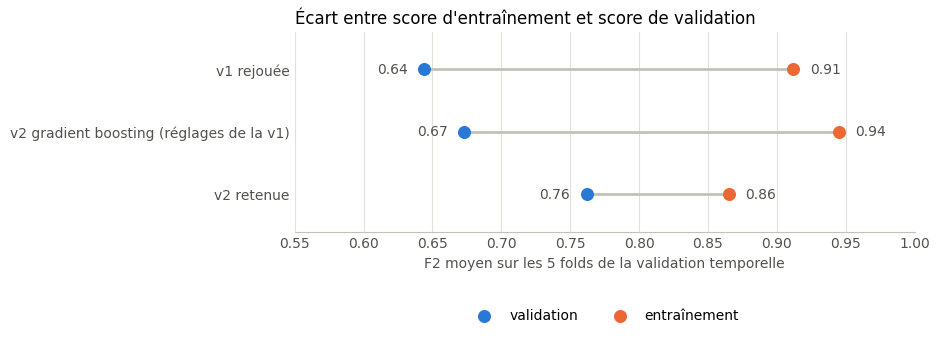

In [17]:
BLEU, ORANGE, ENCRE, GRIS = "#2a78d6", "#eb6834", "#52514e", "#c3c2b7"
donnees = tableau(*comparaison)[::-1]

fig, ax = plt.subplots(figsize=(8, 2.6))
for y, (nom, ligne) in enumerate(donnees.iterrows()):
    ax.plot([ligne["F2 validation"], ligne["F2 entraînement"]], [y, y], color=GRIS, linewidth=2, zorder=1)
    ax.text(ligne["F2 validation"] - 0.012, y, f"{ligne['F2 validation']:.2f}", ha="right", va="center", color=ENCRE)
    ax.text(ligne["F2 entraînement"] + 0.012, y, f"{ligne['F2 entraînement']:.2f}", ha="left", va="center", color=ENCRE)
ax.scatter(donnees["F2 validation"], range(len(donnees)), s=70, color=BLEU, label="validation", zorder=2)
ax.scatter(donnees["F2 entraînement"], range(len(donnees)), s=70, color=ORANGE, label="entraînement", zorder=2)
ax.set_yticks(range(len(donnees)), donnees.index)
ax.set_xlim(0.55, 1.0)
ax.set_ylim(-0.6, len(donnees) - 0.4)
ax.set_xlabel("F2 moyen sur les 5 folds de la validation temporelle", color=ENCRE)
ax.set_title("Écart entre score d'entraînement et score de validation", loc="left")
ax.tick_params(colors=ENCRE, length=0)
ax.grid(axis="x", color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
for cote in ["top", "right", "left"]:
    ax.spines[cote].set_visible(False)
ax.spines["bottom"].set_color(GRIS)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=2)
plt.show()

L'écart passe de 0,268 (v1 rejouée) à 0,103 (v2 retenue).

- Gradient boosting avec les réglages de la v1 : 0,945 à l'entraînement, 0,673 en validation.
- Après réglage : 0,865 et 0,762.
- Profondeur des arbres : sans limite, l'écart moyen des essais est de 0,216 pour 0,687 en validation ; à 4 niveaux, 0,127 pour 0,749.
- L'écart restant ne vient pas seulement du surapprentissage : chaque fold valide sur une période plus récente. La régression logistique garde 0,128 d'écart.

### Poids des variables

Le pipeline retenu est revalidé sans certaines variables : les variables nouvelles, puis les trois colonnes dont le moment de saisie est incertain (tâche 4).

In [18]:
def sans_variables(retirees):
    """Le pipeline retenu, privé de quelques variables préparées."""
    p = build_pipeline()
    preparation = p.named_steps["preprocessing"]
    preparation.transformers = [
        (nom, etape, [c for c in colonnes if c not in retirees]) for nom, etape, colonnes in preparation.transformers
    ]
    return p


valider("v2 sans agent_id", sans_variables(["agent_id"]), X_train)
valider("v2 sans aucune variable nouvelle", sans_variables(NEW_CATEGORICAL + NEW_NUMERICAL), X_train)
douteuses = ["country", "required_car_parking_spaces", "total_of_special_requests"]
valider("v2 sans pays, parking ni demandes", sans_variables(douteuses), X_train)
tableau("v2 retenue", "v2 sans agent_id", "v2 sans aucune variable nouvelle", "v2 sans pays, parking ni demandes")

,F2 validation,écart-type,F2 entraînement,écart entr. - val.,rappel,précision,ROC AUC
v2 retenue,0.762,0.079,0.865,0.103,0.751,0.820,0.907
v2 sans agent_id,0.733,0.091,0.858,0.126,0.717,0.809,0.900
v2 sans aucune variable nouvelle,0.725,0.097,0.859,0.134,0.708,0.813,0.899
"v2 sans pays, parking ni demandes",0.656,0.091,0.745,0.089,0.640,0.769,0.825


- Variables nouvelles : +0,037 point de F2 (0,725 sans elles, 0,762 avec). L'essentiel vient de `agent_id` (0,733 sans lui).
- Sans le pays, le parking et les demandes particulières : F2 de 0,656, ROC AUC de 0,825 contre 0,907. Le modèle dépend de ces trois colonnes.

### Seuil de décision

`predict` répond « annulée » à partir d'une probabilité de 0,5. Les prédictions des 5 folds de validation, sur l'entraînement, donnent les scores à d'autres seuils.

In [19]:
probas, reels = [], []
for i_train, i_val in CV.split(X_train):
    modele = build_pipeline().fit(X_train.iloc[i_train], y_train.iloc[i_train])
    probas.append(modele.predict_proba(X_train.iloc[i_val])[:, 1])
    reels.append(y_train.iloc[i_val])
probas, reels = np.concatenate(probas), pd.concat(reels)

pd.DataFrame(
    {
        seuil: {
            "F2": fbeta_score(reels, probas >= seuil, beta=2),
            "rappel": recall_score(reels, probas >= seuil),
            "précision": precision_score(reels, probas >= seuil),
        }
        for seuil in [0.3, 0.4, 0.5, 0.6]
    }
).T.rename_axis("seuil").round(3)

,F2,rappel,précision
seuil,,,
0.3,0.806,0.856,0.654
0.4,0.792,0.805,0.744
0.5,0.765,0.754,0.812
0.6,0.685,0.650,0.876


À 0,3, le F2 de validation passe de 0,765 à 0,806 : rappel de 0,754 à 0,856, précision de 0,812 à 0,654.

Le seuil reste à 0,5 pour le verdict. C'est celui de `predict`, et la v1 est comparée au même seuil.

## Tâche 8 — Verdict

### Choix de la métrique

- Annulation ratée (faux négatif) : le modèle a prédit « maintenue », la chambre reste vide. L'hôtel perd le séjour.
- Annulation prédite à tort (faux positif) : l'hôtel relance un client qui serait venu, ou revend la chambre en surréservation. Le coût est faible pour une relance, plus élevé si un client doit être relogé.

Une annulation ratée coûte plus cher qu'une fausse alerte. La métrique principale est le F2 de la classe « annulée », où le rappel pèse deux fois plus que la précision. Le rappel, la précision et le ROC AUC sont donnés à côté. L'*accuracy* n'est pas retenue : elle donne le même poids aux deux erreurs.

### Évaluation sur le jeu de test

Les deux modèles sont entraînés sur le même jeu d'entraînement et évalués une fois sur les mêmes 4 mois, au seuil de 0,5.

In [20]:
y_test = test[TARGET]  # première et seule utilisation du jeu de test
print(f"Test : {len(test)} réservations, arrivées du {test['arrival_date'].min().date()} au {test['arrival_date'].max().date()}, taux d'annulation {y_test.mean():.1%}")


def verdict(pipeline, colonnes):
    debut = time.perf_counter()
    pipeline.fit(train[colonnes], y_train)
    duree = time.perf_counter() - debut
    with tempfile.TemporaryDirectory() as dossier:
        chemin = Path(dossier) / "modele.joblib"
        joblib.dump(pipeline, chemin)
        taille = chemin.stat().st_size / 1e6
    mesures = evaluate(pipeline, test[colonnes], y_test)
    confusion = mesures.pop("confusion_matrix")
    return {**mesures, **confusion, "entraînement (s)": round(duree, 1), "taille (Mo)": round(taille, 2)}, pipeline


resultat_v1, v1 = verdict(build_v1(), V1_FEATURES)
resultat_v2, v2 = verdict(build_pipeline(), RAW_FEATURES)
resultats = pd.DataFrame({"v1 rejouée": resultat_v1, "v2": resultat_v2})
resultats

Test : 19911 réservations, arrivées du 2016-09-01 au 2016-12-31, taux d'annulation 38.0%


,v1 rejouée,v2
f2,0.4691,0.4963
recall,0.4177,0.4465
precision,0.9235,0.8966
f1,0.5752,0.5961
roc_auc,0.8669,0.8987
average_precision,0.8278,0.8573
tn,12079.0000,11951.0000
fp,262.0000,390.0000
fn,4408.0000,4190.0000
tp,3162.0000,3380.0000


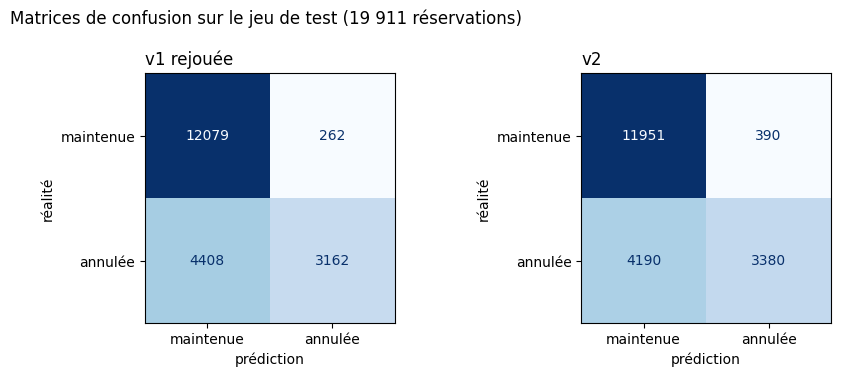

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (nom, modele, colonnes) in zip(axes, [("v1 rejouée", v1, V1_FEATURES), ("v2", v2, RAW_FEATURES)]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, modele.predict(test[colonnes]), display_labels=["maintenue", "annulée"],
        cmap="Blues", colorbar=False, values_format="d", ax=ax,
    )
    ax.set_title(nom, loc="left")
    ax.set_xlabel("prédiction")
    ax.set_ylabel("réalité")
fig.suptitle("Matrices de confusion sur le jeu de test (19 911 réservations)", x=0.02, ha="left")
fig.tight_layout()
plt.show()

In [22]:
# Rappel et précision par mois d'arrivée du jeu de test
mois = test["arrival_date"].dt.strftime("%Y-%m")
lignes = {}
for nom, modele, colonnes in [("v1 rejouée", v1, V1_FEATURES), ("v2", v2, RAW_FEATURES)]:
    prediction = pd.Series(modele.predict(test[colonnes]), index=test.index)
    for m in sorted(mois.unique()):
        masque = mois == m
        lignes[(m, nom)] = {
            "annulations réelles": int(y_test[masque].sum()),
            "rappel": round(recall_score(y_test[masque], prediction[masque]), 3),
            "précision": round(precision_score(y_test[masque], prediction[masque]), 3),
        }
pd.DataFrame(lignes).T

,,annulations réelles,rappel,précision
2016-09,v1 rejouée,2022.0,0.463,0.945
2016-10,v1 rejouée,2514.0,0.386,0.974
2016-11,v1 rejouée,1636.0,0.529,0.887
2016-12,v1 rejouée,1398.0,0.280,0.846
2016-09,v2,2022.0,0.617,0.895
2016-10,v2,2514.0,0.356,0.948
2016-11,v2,1636.0,0.498,0.894
2016-12,v2,1398.0,0.301,0.813


La v2 obtient un F2 de 0,496, la v1 rejouée 0,469.

- Rappel : 0,447 contre 0,418. Précision : 0,897 contre 0,924.
- Sur 7 570 annulations réelles, la v2 en rate 4 190 et la v1 4 408 (218 de moins). Elle produit 390 fausses alertes contre 262 (128 de plus).
- ROC AUC : 0,899 contre 0,867.
- Entraînement : environ 3 s contre 1,5 s. Taille : 0,47 Mo contre 0,75 Mo.
- Par mois : la v2 a un meilleur rappel en septembre (0,617 contre 0,463) et en décembre, la v1 en octobre et en novembre.
- Écart avec la validation croisée : 0,762 attendu et 0,496 obtenu pour la v2 ; 0,644 et 0,469 pour la v1.

### Annulations ratées

Analyse d'erreurs des deux modèles évalués, sans nouveau réglage : rappel selon le type d'acompte, et probabilité moyenne prédite par la v2 comparée au taux réel.

In [23]:
acompte = test["deposit_type"].where(test["deposit_type"] == "Non Refund", "No Deposit ou Refundable")
proba_v2 = pd.Series(v2.predict_proba(test[RAW_FEATURES])[:, 1], index=test.index)
lignes = {}
for groupe in sorted(acompte.unique()):
    masque = (acompte == groupe) & (y_test == 1)
    lignes[groupe] = {
        "annulations réelles": int(masque.sum()),
        "rappel v1 rejouée": round(v1.predict(test.loc[masque, V1_FEATURES]).mean(), 3),
        "rappel v2": round(v2.predict(test.loc[masque, RAW_FEATURES]).mean(), 3),
    }
print(f"Probabilité moyenne prédite par la v2 : {proba_v2.mean():.3f} | taux d'annulation réel : {y_test.mean():.3f}")
print(f"Probabilité médiane donnée par la v2 aux annulations ratées : {proba_v2[(y_test == 1) & (proba_v2 < 0.5)].median():.2f}")
pd.DataFrame(lignes).T

Probabilité moyenne prédite par la v2 : 0.308 | taux d'annulation réel : 0.380
Probabilité médiane donnée par la v2 aux annulations ratées : 0.27


,annulations réelles,rappel v1 rejouée,rappel v2
No Deposit ou Refundable,5146.0,0.147,0.189
Non Refund,2424.0,0.993,0.993


- Annulations avec acompte non remboursable (2 424) : rappel de 0,993 pour les deux modèles.
- Autres annulations (5 146) : rappel de 0,189 pour la v2 et de 0,147 pour la v1.
- La v2 prédit 30,8 % d'annulations en moyenne. Le taux réel est de 38,0 %.
- Les annulations ratées par la v2 ont une probabilité médiane de 0,27, sous le seuil de 0,5.
- Le ROC AUC reste de 0,899. Le seuil de décision est le premier réglage à étudier, sur des données nouvelles : le jeu de test a servi au verdict.